# 06 - Baseline Models

**Why baselines matter.** A complex model is only useful if it beats a simple, transparent rule. This notebook evaluates two baselines on the same rolling-origin folds as the machine-learning models.

| Baseline | Definition |
|---|---|
| Historical average | mean sales by store x weekday over the training history |
| Seasonal naive | last observed week, same weekday; fallback to 4-week weekday average |

**Validation protocol.** Three expanding-window folds with a 48-day horizon, plus a final holdout. The holdout is never used for model selection.

In [1]:
import sys, json
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110
print("Project root:", PROJECT_ROOT)

Project root: rossmann-sales-forecasting


In [2]:
results = json.loads((PROJECT_ROOT / "outputs" / "metrics" / "validation_results.json").read_text())
protocol = pd.Series(results["protocol"]).to_frame("value")
display(protocol)

rows = []
for fold, payload in results["folds"].items():
    for model, metrics in payload["models"].items():
        rows.append({"fold": fold, "model": model, "rmspe": metrics["rmspe"], "mae": metrics["mae"],
                     "wape": metrics["wape"], "n_scored": metrics["n_rows_scored"]})
metrics_frame = pd.DataFrame(rows)
display(metrics_frame.pivot(index="model", columns="fold", values="rmspe").round(4))

,value
horizon_days,48
fold_type,rolling origin / expanding window
metric,RMSPE on open days with positive sales


fold,fold_1,fold_2,fold_3,holdout
model,,,,
ensemble_xgb_hist,0.2303,0.1772,0.1553,0.1381
historical_average,0.2625,0.2616,0.2189,0.2283
linear_regression,0.3500,0.2716,0.2380,0.2209
random_forest,0.2827,0.2041,0.1742,0.1700
seasonal_naive,0.3966,0.3502,0.4967,0.2304
xgboost,0.2546,0.1911,0.1744,0.1714


## 1. How the baselines behave across time

The historical average is stable and hard to beat on a 48-day horizon: it already embeds the store's level and weekly pattern. The seasonal naive is more sensitive to the most recent week; it wins in stable periods and loses when the last week is atypical (a holiday, a heat wave, a promotion block).

model,historical_average,seasonal_naive
fold,,
fold_1,0.2625,0.3966
fold_2,0.2616,0.3502
fold_3,0.2189,0.4967
holdout,0.2283,0.2304


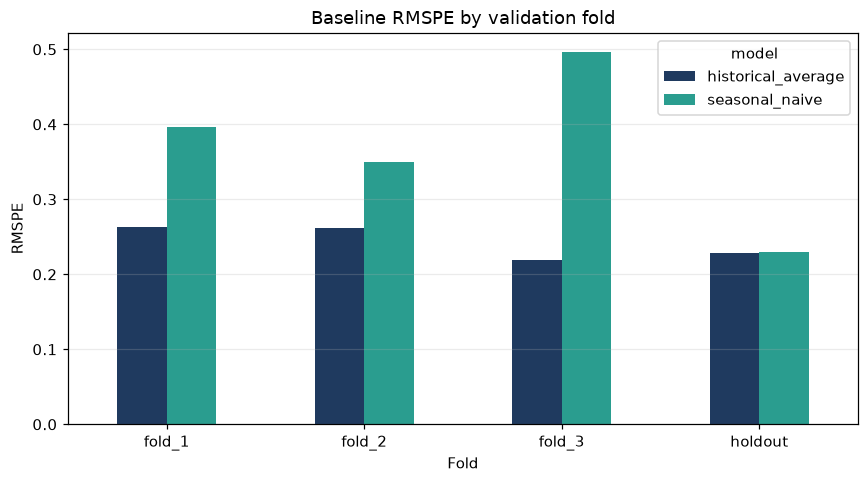

In [3]:
baselines = metrics_frame[metrics_frame.model.isin(["historical_average", "seasonal_naive"])]
pivot = baselines.pivot(index="fold", columns="model", values="rmspe").round(4)
display(pivot)

fig, ax = plt.subplots(figsize=(8, 4.5))
pivot.plot(kind="bar", ax=ax, color=["#1f3a5f", "#2a9d8f"])
ax.set_title("Baseline RMSPE by validation fold")
ax.set_ylabel("RMSPE")
ax.set_xlabel("Fold")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 2. Why a global model can beat a per-store average

A store-weekday average ignores:

* promotions on the target day,
* holidays and school holidays,
* the recent level of the store (it averages over 2.5 years),
* interactions between store type and seasonality.

A global model can learn these effects across all stores and still use the store's own history as a feature. That is the hypothesis tested in notebook 07.

## 3. Baseline diagnostics

The table below shows the absolute error and WAPE. WAPE is useful because it weights errors by sales volume; RMSPE weights small stores more heavily. A model can look good on one and mediocre on the other, which is why both are reported.

In [4]:
summary = pd.DataFrame(results["summary"]).round(4)
display(summary)

holdout = metrics_frame[metrics_frame.fold == "holdout"].sort_values("rmspe")
display(holdout.round(4))

,model,mean_rmspe,std_rmspe,mean_mae,mean_wape
0,ensemble_xgb_hist,0.1752,0.0400,862.7193,0.1217
1,xgboost,0.1979,0.0388,989.2680,0.1395
2,random_forest,0.2078,0.0522,973.5796,0.1374
3,historical_average,0.2428,0.0225,1204.8148,0.1699
4,linear_regression,0.2701,0.0573,1172.1670,0.1655
5,seasonal_naive,0.3685,0.1105,1789.1057,0.2522


,fold,model,rmspe,mae,wape,n_scored
23,holdout,ensemble_xgb_hist,0.1381,826.6725,0.1157,45852
21,holdout,random_forest,0.1700,913.5443,0.1279,45852
22,holdout,xgboost,0.1714,1008.1900,0.1411,45852
20,holdout,linear_regression,0.2209,1202.8072,0.1684,45852
18,holdout,historical_average,0.2283,1259.3611,0.1763,45852
19,holdout,seasonal_naive,0.2304,1466.6554,0.2053,45852


**Interpretation.** On the holdout, the historical average reaches RMSPE 0.2283, while seasonal naive is close behind at 0.2304. Both are far from the accuracy of a properly regularised model - but they set the bar that any machine-learning model must clear, and the historical average later becomes the 35% anchor of the selected ensemble (RMSPE 0.1381).

**Business meaning.** If a store has no usable history for a new weekday pattern, the store-weekday average is a safe fallback. The production system should keep it as a guardrail: never let the ML model deviate by more than a sensible band from the store's own historical average.